# Turning actions into tokens

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/3_robot_learning/05_action_tokenisation.ipynb) &nbsp; Guide note: [guide-robot-policies](https://www.matthewwnuk.com/guide-robot-policies.html#tokenise)

A language model outputs tokens, so a policy built on one has to write actions as tokens. The simple way
is to sort each value into a bin. It works and it is long: a five-second chunk is 350 tokens. Because
robot motion is smooth, a change of basis makes it far shorter. This notebook does both on real action
chunks.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import numpy as np, matplotlib.pyplot as plt
from scipy.fft import dct, idct
from guide_utils import data, style
style.use()
d = data.libero(); A, EP = d["action"], d["episode"]; H = 50                           # 50 steps = 5 seconds
lo, hi = np.percentile(A, 1, 0), np.percentile(A, 99, 0)
chunks = np.array([np.clip(2 * (A[EP == e][i:i + H] - lo) / (hi - lo) - 1, -1, 1) for e in np.unique(EP)[:200] for i in range(0, (EP == e).sum() - H, H)])
print("chunks:", chunks.shape, "= (chunk, step, action value), normalised to -1..1")

chunks: (977, 50, 7) = (chunk, step, action value), normalised to -1..1


## Binning

Divide the range into equal bins and replace each value with its bin number.

In [3]:
def to_bins(x, n): return np.round((x + 1) / 2 * (n - 1)).astype(int)
def from_bins(b, n): return b / (n - 1) * 2 - 1
for n in (16, 64, 256, 1024): print(f"{n:5d} bins: mean rounding error {np.abs(from_bins(to_bins(chunks, n), n) - chunks).mean():.4f} of a range of 2")
print(f"\none chunk as bins: {H} steps x 7 values = {H * 7} tokens"); print("first step:", to_bins(chunks[7, 0], 256).tolist())

   16 bins: mean rounding error 0.0262 of a range of 2
   64 bins: mean rounding error 0.0063 of a range of 2
  256 bins: mean rounding error 0.0015 of a range of 2
 1024 bins: mean rounding error 0.0004 of a range of 2

one chunk as bins: 50 steps x 7 values = 350 tokens
first step: [125, 142, 159, 36, 90, 102, 0]


256 bins are precise enough. The problem is the count, and that neighbouring tokens are almost the same,
so predicting the next one teaches the model very little.

In [4]:
tok = to_bins(chunks, 256); print(f"a token equals the one before it (same action value, next step) {np.mean(tok[:, 1:] == tok[:, :-1]):.0%} of the time")

a token equals the one before it (same action value, next step) 42% of the time


## A basis in which motion is sparse

The discrete cosine transform rewrites a signal as a sum of cosines of increasing frequency.
Smooth signals need only the first few.

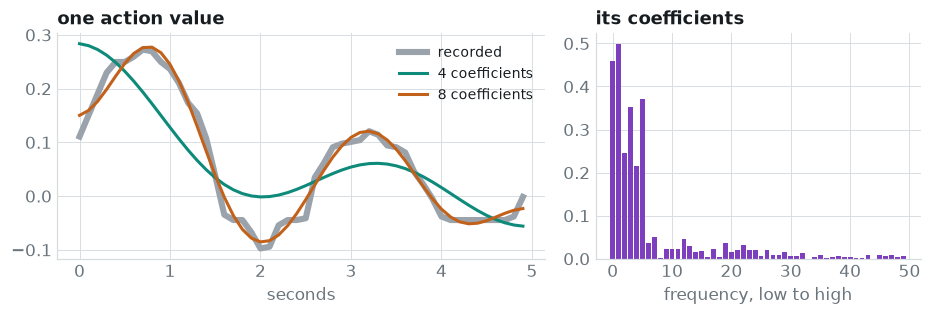

In [5]:
Z = dct(chunks, axis=1, norm="ortho"); ex, dim = 7, 1; t = np.arange(H) / 10
def keep(z, k): out = z.copy(); out[k:] = 0; return idct(out, axis=0, norm="ortho")
fig, ax = plt.subplots(1, 2, figsize=(8.6, 3), gridspec_kw=dict(width_ratios=[1.5, 1]))
ax[0].plot(t, chunks[ex, :, dim], color=style.GREY, lw=4, label="recorded"); ax[0].plot(t, keep(Z[ex, :, dim], 4), label="4 coefficients"); ax[0].plot(t, keep(Z[ex, :, dim], 8), label="8 coefficients"); ax[0].set_xlabel("seconds"); ax[0].legend(fontsize=9); ax[0].set_title("one action value")
ax[1].bar(range(H), np.abs(Z[ex, :, dim]), color=style.PURPLE); ax[1].set_xlabel("frequency, low to high"); ax[1].set_title("its coefficients"); plt.tight_layout(); plt.show()

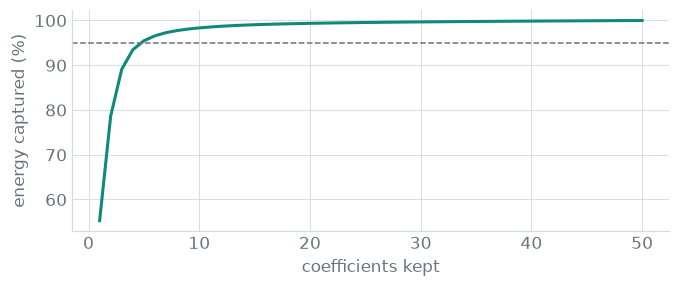

5 of 50 coefficients carry 95% of the energy, averaged over 977 chunks


In [6]:
energy = (Z ** 2).mean((0, 2)); cum = np.cumsum(energy) / energy.sum(); k95 = int(np.searchsorted(cum, 0.95)) + 1
plt.figure(figsize=(7, 2.6)); plt.plot(range(1, H + 1), cum * 100); plt.axhline(95, color=style.MUTED, ls="--", lw=1); plt.xlabel("coefficients kept"); plt.ylabel("energy captured (%)"); plt.show()
print(f"{k95} of {H} coefficients carry 95% of the energy, averaged over {len(chunks)} chunks")

## From coefficients to tokens

Round the coefficients to integers. Most become zero. What is left is a short list of small integers,
and a general-purpose compressor such as byte-pair encoding shortens it again.

scale  5:    69 non-zero values per chunk of 350   reconstruction error 0.035
scale 10:    95 non-zero values per chunk of 350   reconstruction error 0.021
scale 20:   133 non-zero values per chunk of 350   reconstruction error 0.012
scale 40:   185 non-zero values per chunk of 350   reconstruction error 0.007


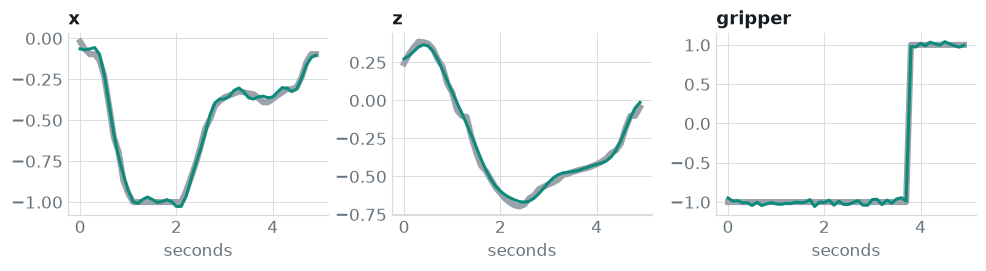

In [7]:
for scale in (5, 10, 20, 40):
    q = np.round(Z * scale); rec = idct(q / scale, axis=1, norm="ortho"); print(f"scale {scale:2d}: {np.mean((q != 0).sum((1, 2))):5.0f} non-zero values per chunk of {H * 7}   reconstruction error {np.sqrt(((rec - chunks) ** 2).mean()):.3f}")
q = np.round(Z * 10); rec = idct(q / 10, axis=1, norm="ortho"); fig, ax = plt.subplots(1, 3, figsize=(9, 2.6))
for a, dim, n in zip(ax, (0, 2, 6), ("x", "z", "gripper")): a.plot(t, chunks[ex, :, dim], color=style.GREY, lw=4); a.plot(t, rec[ex, :, dim], color=style.TEAL); a.set_title(n); a.set_xlabel("seconds")
plt.tight_layout(); plt.show()

The gripper command is the exception. It is a step, not a smooth curve, and a step needs many
frequencies. Look at how its reconstruction rings around the switch.

## Things to try

- Use 20-step chunks. Does a shorter chunk compress better or worse per step?
- Compress the gripper value by run-length encoding instead of the transform.
- Apply byte-pair encoding to the rounded coefficients: repeatedly merge the most frequent adjacent pair.